# Fig. 11: real-world ×4 SR on RealSR, with OSEDiff

**Data and protocol.** The inputs are the RealSR test pairs distributed with OSEDiff (`preset/datasets/benchmark_realsr`): 128×128 LR crops and their registered 512×512 HR crops. This is the protocol of Table X, so the figure and the table now rest on the same data. The OSEDiff column uses the official OSEDiff results on this benchmark shipped in the same folder, which were produced by the OSEDiff authors with their default settings.

**Models.** Bicubic; BSRGAN (KAIR release); Real-ESRGAN (`RealESRGAN_x4plus`); Real-SwinIR (`003_realSR_BSRGAN_DFO_s64w8_SwinIR-M_x4_GAN`); ResShift journal version v3 (4 steps); SinSR v1 (1 step); OSEDiff.

**Hardware.** The run recorded in this notebook used 2 CPU cores and no GPU. ResShift and SinSR are run through a small shim that turns their `.cuda()` calls into no-ops. Results are deterministic for the GAN and SwinIR models; ResShift and SinSR use their default seed (12345).

**Metrics.** PSNR and SSIM on the Y channel with the BasicSR implementation (`calculate_psnr`, `calculate_ssim`, `test_y_channel=True`). For whole images a border of 4 pixels is excluded; for crops, no border is excluded.

## 1. Setup

In [ ]:
import os, sys, subprocess, glob, json, shutil, time
WORK = os.path.abspath('fig11_work'); os.makedirs(WORK, exist_ok=True); os.chdir(WORK)
def sh(cmd, check=True):
    r = subprocess.run(cmd, shell=True, text=True, capture_output=True)
    tail = (r.stdout or '')[-1500:] + (r.stderr or '')[-1500:]
    if r.returncode != 0 and check: print(tail); raise RuntimeError(cmd)
    return r
sh(f'{sys.executable} -m pip install -q torch torchvision opencv-python-headless scikit-image matplotlib pyyaml omegaconf loguru loralib einops timm addict future lmdb yapf scipy tqdm lpips')
REPOS = {'BasicSR': ('XPixelGroup/BasicSR', 'v1.4.2'), 'OSEDiff': ('cswry/OSEDiff', None), 'SwinIR': ('JingyunLiang/SwinIR', None),
         'ResShift': ('zsyOAOA/ResShift', None), 'SinSR': ('wyf0912/SinSR', None)}
for name, (repo, tag) in REPOS.items():
    if not os.path.isdir(name):
        sh(f"git clone -q --depth 1 {'--branch ' + tag if tag else ''} https://github.com/{repo}.git {name}")
# BasicSR 1.4.2 is used from source: write its version file and fix an import removed in torchvision 0.17
open('BasicSR/basicsr/version.py', 'w').write("__version__ = '1.4.2'\n__gitsha__ = 'unknown'\nversion_info = (1, 4, 2)\n")
for root in ('BasicSR', 'SinSR'):
    for f in glob.glob(f'{root}/**/*.py', recursive=True):
        t = open(f, errors='ignore').read()
        if 'torchvision.transforms.functional_tensor' in t:
            open(f, 'w').write(t.replace('torchvision.transforms.functional_tensor', 'torchvision.transforms.functional'))
if not os.path.exists('SinSR/basicsr/version.py'):
    open('SinSR/basicsr/version.py', 'w').write("__version__ = '1.3.4'\n__gitsha__ = 'unknown'\n")
sys.path.insert(0, os.path.join(WORK, 'BasicSR'))
import torch; print('torch', torch.__version__, '| CUDA:', torch.cuda.is_available(), '| CPU threads:', torch.get_num_threads())

torch 2.15.0+cu132 | CUDA: False | CPU threads: 2


## 2. Official weights

In [ ]:
W = os.path.join(WORK, 'weights'); os.makedirs(W, exist_ok=True)
URLS = {
    'RealESRGAN_x4plus.pth': 'https://github.com/xinntao/Real-ESRGAN/releases/download/v0.1.0/RealESRGAN_x4plus.pth',
    'BSRGAN.pth': 'https://github.com/cszn/KAIR/releases/download/v1.0/BSRGAN.pth',
    '003_realSR_BSRGAN_DFO_s64w8_SwinIR-M_x4_GAN.pth': 'https://github.com/JingyunLiang/SwinIR/releases/download/v0.0/003_realSR_BSRGAN_DFO_s64w8_SwinIR-M_x4_GAN.pth',
    'resshift_realsrx4_s4_v3.pth': 'https://github.com/zsyOAOA/ResShift/releases/download/v2.0/resshift_realsrx4_s4_v3.pth',
    'autoencoder_vq_f4.pth': 'https://github.com/zsyOAOA/ResShift/releases/download/v2.0/autoencoder_vq_f4.pth',
    'SinSR_v1.pth': 'https://github.com/wyf0912/SinSR/releases/download/v1.0/SinSR_v1.pth',
}
for f, u in URLS.items():
    p = os.path.join(W, f)
    if not os.path.exists(p): sh(f'curl -sL --max-time 1200 -o {p} {u}')
    print(f'{f:50s} {os.path.getsize(p) / 2**20:8.1f} MB')
for repo in ('ResShift', 'SinSR'):
    os.makedirs(f'{repo}/weights', exist_ok=True)
for f, repo in [('resshift_realsrx4_s4_v3.pth', 'ResShift'), ('autoencoder_vq_f4.pth', 'ResShift'),
                ('SinSR_v1.pth', 'SinSR'), ('autoencoder_vq_f4.pth', 'SinSR')]:
    dst = f'{repo}/weights/{f}'
    if not os.path.exists(dst): os.symlink(os.path.join(W, f), dst)

RealESRGAN_x4plus.pth                                  63.9 MB


BSRGAN.pth                                             63.9 MB


003_realSR_BSRGAN_DFO_s64w8_SwinIR-M_x4_GAN.pth        64.0 MB


resshift_realsrx4_s4_v3.pth                           455.8 MB


autoencoder_vq_f4.pth                                 211.1 MB


SinSR_v1.pth                                          455.8 MB


## 3. Test data: RealSR pairs and official OSEDiff results

In [ ]:
import cv2, numpy as np
NAMES = ['Canon_026', 'Nikon_031', 'Canon_041']
B = 'OSEDiff/preset/datasets/benchmark_realsr'
for d in ('data/lr', 'data/hr', 'out/OSEDiff'): os.makedirs(d, exist_ok=True)
for n in NAMES:
    shutil.copy(f'{B}/test_LR/{n}_LR4.png', f'data/lr/{n}.png')
    shutil.copy(f'{B}/test_HR/{n}_LR4.png', f'data/hr/{n}.png')
    shutil.copy(f'{B}/results_osediff/{n}_LR4.png', f'out/OSEDiff/{n}.png')
    print(n, 'LR', cv2.imread(f'data/lr/{n}.png').shape, 'HR', cv2.imread(f'data/hr/{n}.png').shape)
# registration check: shift between the bicubically upsampled LR and the HR crop
for n in NAMES:
    hr = cv2.imread(f'data/hr/{n}.png', 0).astype(np.float32)
    up = cv2.resize(cv2.imread(f'data/lr/{n}.png', 0), (512, 512), interpolation=cv2.INTER_CUBIC).astype(np.float32)
    (dx, dy), _ = cv2.phaseCorrelate(up, hr); print(f'{n}: residual shift dx={dx:.2f}, dy={dy:.2f} px')

Canon_026 LR (128, 128, 3) HR (512, 512, 3)
Nikon_031 LR (128, 128, 3) HR (512, 512, 3)
Canon_041 LR (128, 128, 3) HR (512, 512, 3)
Canon_026: residual shift dx=0.00, dy=0.01 px
Nikon_031: residual shift dx=0.02, dy=0.02 px
Canon_041: residual shift dx=-0.01, dy=0.00 px


## 4. Inference

In [ ]:
sys.path.insert(0, os.path.join(WORK, 'SwinIR'))
from basicsr.archs.rrdbnet_arch import RRDBNet
from models.network_swinir import SwinIR
torch.set_num_threads(max(1, os.cpu_count()))
dev = 'cuda' if torch.cuda.is_available() else 'cpu'

def load_rrdb(path, kair=False):
    net = RRDBNet(3, 3, num_feat=64, num_block=23, num_grow_ch=32, scale=4)
    sd = torch.load(path, map_location='cpu'); sd = sd.get('params_ema', sd)
    if kair:  # KAIR parameter names -> BasicSR names (identical architecture)
        rep = [('RRDB_trunk.', 'body.'), ('.RDB1.', '.rdb1.'), ('.RDB2.', '.rdb2.'), ('.RDB3.', '.rdb3.'), ('trunk_conv', 'conv_body'),
               ('upconv1', 'conv_up1'), ('upconv2', 'conv_up2'), ('HRconv', 'conv_hr')]
        new = {}
        for k, v in sd.items():
            for a, b in rep: k = k.replace(a, b)
            new[k] = v
        sd = new
    net.load_state_dict(sd, strict=True); return net.eval().to(dev)

def load_real_swinir(path):  # configuration of SwinIR-M for real-world SR (main_test_swinir.py, task real_sr)
    net = SwinIR(upscale=4, in_chans=3, img_size=64, window_size=8, img_range=1., depths=[6] * 6, embed_dim=180,
                 num_heads=[6] * 6, mlp_ratio=2, upsampler='nearest+conv', resi_connection='1conv')
    sd = torch.load(path, map_location='cpu'); net.load_state_dict(sd.get('params_ema', sd), strict=True); return net.eval().to(dev)

def infer(net, lr_bgr, pad_to=1):
    x = torch.from_numpy(cv2.cvtColor(lr_bgr, cv2.COLOR_BGR2RGB)).permute(2, 0, 1)[None].float().div(255.).to(dev)
    h, w = x.shape[2:]; ph, pw = (-h) % pad_to, (-w) % pad_to
    if ph or pw: x = torch.nn.functional.pad(x, (0, pw, 0, ph), mode='reflect')
    with torch.no_grad(): y = net(x)[..., :4 * h, :4 * w]
    return cv2.cvtColor((y.clamp(0, 1)[0].permute(1, 2, 0).cpu().numpy() * 255.).round().astype(np.uint8), cv2.COLOR_RGB2BGR)

for m, build, pad in [('BSRGAN', lambda: load_rrdb(f'{W}/BSRGAN.pth', kair=True), 1),
                      ('Real-ESRGAN', lambda: load_rrdb(f'{W}/RealESRGAN_x4plus.pth'), 1),
                      ('Real-SwinIR', lambda: load_real_swinir(f'{W}/003_realSR_BSRGAN_DFO_s64w8_SwinIR-M_x4_GAN.pth'), 8)]:
    net = build(); os.makedirs(f'out/{m}', exist_ok=True)
    for n in NAMES:
        t = time.time(); cv2.imwrite(f'out/{m}/{n}.png', infer(net, cv2.imread(f'data/lr/{n}.png'), pad))
        print(f'{m:12s} {n}  {time.time() - t:.1f} s')
    del net

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/usr/local/lib/python3.13/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


BSRGAN       Canon_026  4.2 s


BSRGAN       Nikon_031  4.0 s


BSRGAN       Canon_041  4.0 s


Real-ESRGAN  Canon_026  4.1 s


Real-ESRGAN  Nikon_031  4.0 s


Real-ESRGAN  Canon_041  3.8 s


/usr/local/lib/python3.13/site-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/TensorShape.cpp:4207.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


Real-SwinIR  Canon_026  4.7 s


Real-SwinIR  Nikon_031  4.8 s


Real-SwinIR  Canon_041  4.5 s


In [ ]:
SHIM = os.path.join(WORK, 'cpu_shim.py')
open(SHIM, 'w').write('''import sys, os, runpy, torch, contextlib
torch.Tensor.cuda = lambda self, *a, **k: self
torch.nn.Module.cuda = lambda self, *a, **k: self
torch.cuda.set_device = lambda *a, **k: None
torch.cuda.device_count = lambda: 1
torch.cuda.is_available = lambda: False
torch.cuda.manual_seed_all = lambda *a, **k: None
torch.cuda.amp.autocast = lambda *a, **k: contextlib.nullcontext()
_load = torch.load
torch.load = lambda f, map_location=None, **k: _load(f, map_location="cpu", **{**k, "weights_only": False})
script = sys.argv[1]; sys.argv = sys.argv[1:]; sys.path.insert(0, os.path.dirname(os.path.abspath(script)))
runpy.run_path(script, run_name="__main__")
''')
launcher = '' if torch.cuda.is_available() else f'{sys.executable} {SHIM}'
run = lambda cmd: f'{launcher} {cmd}' if launcher else f'{sys.executable} {cmd}'
t = time.time()
sh(f'cd ResShift && {run("inference_resshift.py")} -i {WORK}/data/lr -o {WORK}/out/ResShift --task realsr --scale 4 --version v3 --chop_size 512')
print(f'ResShift done in {time.time() - t:.0f} s'); t = time.time()
# SinSR writes its outputs before importing its optional evaluation module (pyiqa), so a missing pyiqa is harmless
sh(f'cd SinSR && {run("inference.py")} -i {WORK}/data/lr -o {WORK}/out/SinSR --scale 4 --one_step', check=False)
print(f'SinSR done in {time.time() - t:.0f} s')
for m in ('ResShift', 'SinSR'): print(m, sorted(os.listdir(f'out/{m}')))

ResShift done in 129 s


SinSR done in 136 s
ResShift ['Canon_026.png', 'Canon_041.png', 'Nikon_031.png']
SinSR ['Canon_026.png', 'Canon_041.png', 'Nikon_031.png']


## 5. Metrics and figure

In [ ]:
from basicsr.metrics import calculate_psnr, calculate_ssim
import matplotlib; import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
METHODS = ['Bicubic', 'BSRGAN', 'Real-ESRGAN', 'Real-SwinIR', 'ResShift', 'SinSR', 'OSEDiff']
BOXES = {'Canon_026': (150, 60, 200, 150), 'Nikon_031': (220, 20, 280, 210), 'Canon_041': (176, 150, 200, 150)}  # HR (x, y, w, h)

def get_sr(m, n):
    lr = cv2.imread(f'data/lr/{n}.png')
    return cv2.resize(lr, (512, 512), interpolation=cv2.INTER_CUBIC) if m == 'Bicubic' else cv2.imread(f'out/{m}/{n}.png')

RES = {}
for n in NAMES:
    hr = cv2.imread(f'data/hr/{n}.png'); x, y, w, h = BOXES[n]
    for m in METHODS:
        sr = get_sr(m, n); assert sr.shape == hr.shape, (m, n, sr.shape)
        RES.setdefault(n, {})[m] = {
            'psnr_y': calculate_psnr(sr, hr, 4, test_y_channel=True), 'ssim_y': calculate_ssim(sr, hr, 4, test_y_channel=True),
            'crop_psnr_y': calculate_psnr(sr[y:y+h, x:x+w], hr[y:y+h, x:x+w], 0, test_y_channel=True),
            'crop_ssim_y': calculate_ssim(sr[y:y+h, x:x+w], hr[y:y+h, x:x+w], 0, test_y_channel=True)}
print(f"{'image':10s} {'method':12s} {'PSNR':>7s} {'SSIM':>7s} | {'crop PSNR':>9s} {'crop SSIM':>9s}")
for n in NAMES:
    for m in METHODS:
        r = RES[n][m]; print(f"{n:10s} {m:12s} {r['psnr_y']:7.2f} {r['ssim_y']:7.4f} | {r['crop_psnr_y']:9.2f} {r['crop_ssim_y']:9.4f}")

image      method          PSNR    SSIM | crop PSNR crop SSIM
Canon_026  Bicubic        23.77  0.6090 |     22.63    0.5352
Canon_026  BSRGAN         23.95  0.6350 |     22.86    0.5852
Canon_026  Real-ESRGAN    24.09  0.6411 |     23.30    0.5898
Canon_026  Real-SwinIR    24.07  0.6548 |     23.30    0.6123
Canon_026  ResShift       24.20  0.6257 |     23.29    0.5722
Canon_026  SinSR          23.66  0.6059 |     22.49    0.5439
Canon_026  OSEDiff        23.09  0.6201 |     22.26    0.5678
Nikon_031  Bicubic        27.95  0.8920 |     26.93    0.8608
Nikon_031  BSRGAN         28.04  0.9060 |     26.96    0.8725
Nikon_031  Real-ESRGAN    26.21  0.9056 |     24.39    0.8738
Nikon_031  Real-SwinIR    26.66  0.9056 |     25.58    0.8738
Nikon_031  ResShift       26.21  0.8218 |     24.98    0.7759
Nikon_031  SinSR          28.10  0.8933 |     26.26    0.8501
Nikon_031  OSEDiff        25.36  0.8837 |     24.11    0.8499
Canon_041  Bicubic        20.30  0.4457 |     19.85    0.3962
Canon_04

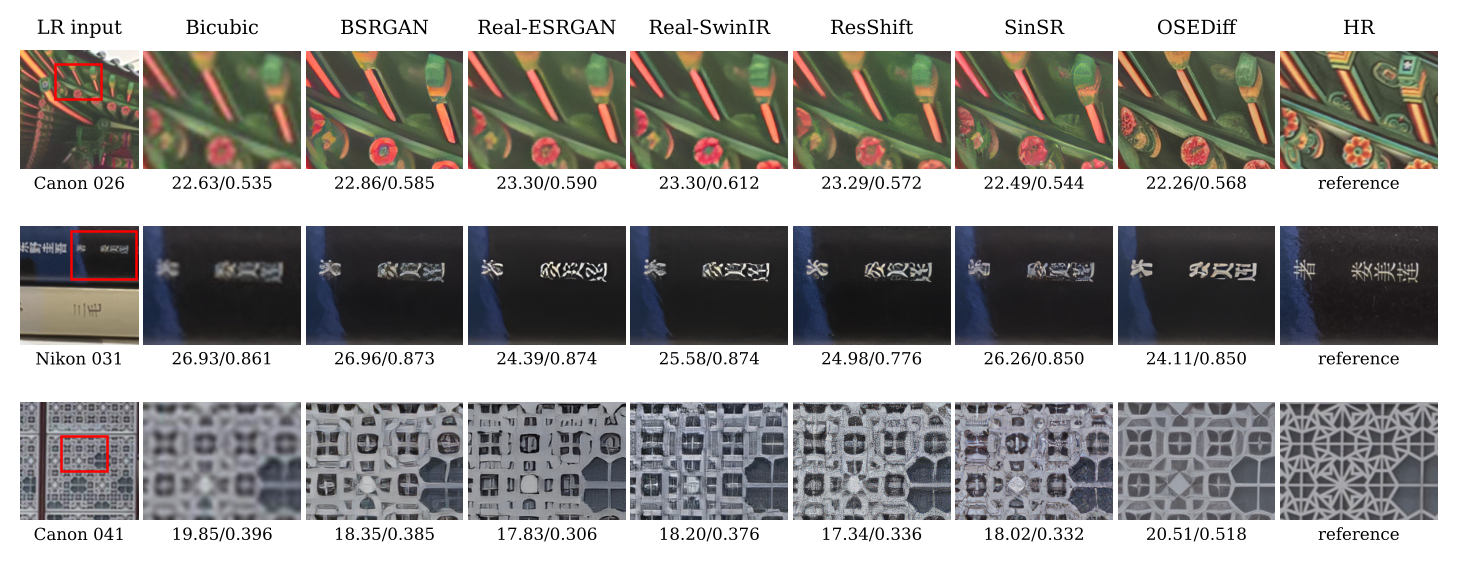

In [ ]:
plt.rcParams.update({'font.family': 'serif', 'font.size': 7})
def render(label_fn, path):
    fig, axes = plt.subplots(3, 9, figsize=(7.16, 2.75), gridspec_kw={'width_ratios': [1.0] + [1.33] * 8})
    for i, n in enumerate(NAMES):
        hr = cv2.imread(f'data/hr/{n}.png'); lr = cv2.imread(f'data/lr/{n}.png'); x, y, w, h = BOXES[n]
        ax = axes[i, 0]; ax.imshow(cv2.cvtColor(lr, cv2.COLOR_BGR2RGB)); ax.axis('off')
        ax.add_patch(Rectangle((x / 4 - .5, y / 4 - .5), w / 4, h / 4, fill=False, ec='red', lw=0.9))
        ax.text(0.5, -0.06, n.replace('_', ' '), transform=ax.transAxes, ha='center', va='top', fontsize=6)
        if i == 0: ax.set_title('LR input', fontsize=7)
        for j, m in enumerate(METHODS + ['HR'], start=1):
            im = hr if m == 'HR' else get_sr(m, n)
            ax = axes[i, j]; ax.imshow(cv2.cvtColor(im[y:y+h, x:x+w], cv2.COLOR_BGR2RGB)); ax.axis('off')
            if i == 0: ax.set_title(m, fontsize=7)
            ax.text(0.5, -0.06, label_fn(RES[n].get(m)) if m != 'HR' else 'reference', transform=ax.transAxes, ha='center', va='top', fontsize=6)
    plt.subplots_adjust(wspace=0.03, hspace=0.22, left=0.005, right=0.995, top=0.94, bottom=0.04)
    os.makedirs('figure', exist_ok=True); fig.savefig(path, dpi=300); fig.savefig(path.replace('.pdf', '.png'), dpi=220); plt.show()

render(lambda r: f"{r['crop_psnr_y']:.2f}/{r['crop_ssim_y']:.3f}", 'figure/fig11_realworld_comparison_v2.pdf')
json.dump({'protocol': 'RealSR x4, 128x128 LR / 512x512 HR test crops from OSEDiff preset/datasets/benchmark_realsr; '
                       'PSNR/SSIM on Y (BasicSR); whole image: border 4; crop: border 0',
           'boxes_hr_xywh': BOXES, 'metrics': RES}, open('figure/fig11_metrics.json', 'w'), indent=1)

## 6. LPIPS

`lpips` downloads the torchvision AlexNet backbone on first use. If the download is blocked, the cell reports this and the values stay empty; run this cell on any machine with normal internet access (CPU is enough, it takes seconds).

In [ ]:
try:
    import lpips
    loss = lpips.LPIPS(net='alex', verbose=False).eval()
    t = lambda im: torch.from_numpy(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)).permute(2, 0, 1)[None].float().div(127.5).sub(1)
    for n in NAMES:
        hr = cv2.imread(f'data/hr/{n}.png'); x, y, w, h = BOXES[n]
        for m in METHODS:
            sr = get_sr(m, n)
            with torch.no_grad():
                RES[n][m]['lpips'] = float(loss(t(sr), t(hr)))
                RES[n][m]['crop_lpips'] = float(loss(t(sr[y:y+h, x:x+w]), t(hr[y:y+h, x:x+w])))
            print(f"{n:10s} {m:12s} LPIPS image {RES[n][m]['lpips']:.4f}  crop {RES[n][m]['crop_lpips']:.4f}")
    render(lambda r: f"{r['crop_psnr_y']:.2f}/{r['crop_lpips']:.3f}", 'figure/fig11_realworld_comparison_v2_lpips.pdf')
    json.dump({'boxes_hr_xywh': BOXES, 'metrics': RES}, open('figure/fig11_metrics.json', 'w'), indent=1)
except Exception as e:
    print('LPIPS not computed here:', type(e).__name__, str(e)[:160])

/usr/local/lib/python3.13/site-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


LPIPS not computed here: URLError <urlopen error Tunnel connection failed: 403 Forbidden>


## 7. Output files


In [ ]:
for p in sorted(glob.glob('figure/*')) + sorted(glob.glob('out/*/*.png')): print(p)

figure/fig11_metrics.json
figure/fig11_realworld_comparison_v2.pdf
figure/fig11_realworld_comparison_v2.png
out/BSRGAN/Canon_026.png
out/BSRGAN/Canon_041.png
out/BSRGAN/Nikon_031.png
out/OSEDiff/Canon_026.png
out/OSEDiff/Canon_041.png
out/OSEDiff/Nikon_031.png
out/Real-ESRGAN/Canon_026.png
out/Real-ESRGAN/Canon_041.png
out/Real-ESRGAN/Nikon_031.png
out/Real-SwinIR/Canon_026.png
out/Real-SwinIR/Canon_041.png
out/Real-SwinIR/Nikon_031.png
out/ResShift/Canon_026.png
out/ResShift/Canon_041.png
out/ResShift/Nikon_031.png
out/SinSR/Canon_026.png
out/SinSR/Canon_041.png
out/SinSR/Nikon_031.png
